# 01 — Data Cleaning & Exploratory Analysis
**Project 03: Hospital Patient Outcomes Dashboard** · TheBuidl Programme Capstone 2026

This notebook takes the raw admissions file, cleans it, engineers the features the brief asks for, and runs the first exploratory analysis.

**Steps**
1. Load and profile the raw data
2. Map the delivered columns to the names used in the brief
3. Clean: parse dates, check length of stay, handle nulls, standardise categories
4. Engineer features: `age_group`, `cost_per_day`, `is_icu_admission`, `weekend_admission` (+ a few extras)
5. Check data completeness by facility
6. EDA: distributions, LOS vs cost correlation, readmission by age group, mortality trend, heatmap, box plot
7. Save `data/cleaned_admissions.csv`

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from matplotlib.colors import LinearSegmentedColormap

pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)

# Chart style: quiet grid, one blue for single-series charts, one-hue sequential ramp for heatmaps
BLUE = '#2a78d6'
CATS = ['#2a78d6', '#eb6834', '#1baf7a', '#eda100', '#e87ba4', '#008300', '#6250d6', '#e34948']
SEQ = LinearSegmentedColormap.from_list('blues', ['#f4f8fd', '#cde2fb', '#86b6ef', '#2a78d6', '#184f95', '#0d366b'])
plt.rcParams.update({
    'figure.facecolor': '#fcfcfb', 'axes.facecolor': '#fcfcfb', 'axes.edgecolor': '#c9c8c2',
    'axes.grid': True, 'grid.color': '#e8e7e2', 'grid.linewidth': 0.8, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.titleweight': 'bold',
    'axes.titlesize': 12, 'axes.labelcolor': '#52514e', 'xtick.color': '#52514e', 'ytick.color': '#52514e',
    'font.size': 10, 'savefig.dpi': 150, 'savefig.bbox': 'tight'})
IMG = '../docs/images/'

## 1. Load and profile the raw data

In [2]:
raw = pd.read_excel('../data/project3_hospital_patients.xlsx')
# Also keep a CSV copy of the raw file under the name the brief uses
raw.to_csv('../data/project3_hospital_outcomes.csv', index=False)
print(raw.shape)
raw.head()

(200, 20)


,patient_id,age,gender,state,insurance_type,admission_date,discharge_date,length_of_stay_days,ward_type,diagnosis_primary,diagnosis_secondary,num_procedures,num_medications,total_bill_naira,amount_paid_naira,discharge_status,readmission_30_days,doctor_id,nurse_ratio,hospital_id
0,PAT00001,68,Female,Abuja,Out-of-Pocket,2022-06-26,2022-07-06,10,General,Malaria,Fracture,4,6,174149.19,110102.20,Referred,1,DR046,6.1,HOSP005
1,PAT00002,63,Male,Oyo,Private,2023-02-13,2023-02-25,12,Paediatric,HIV/AIDS,Anaemia,3,0,667504.14,335503.75,Discharged,0,DR017,3.7,HOSP016
2,PAT00003,23,Female,Rivers,NHIS,2022-09-12,2022-10-24,42,General,Pneumonia,Anaemia,1,9,536071.63,268776.84,Deceased,1,DR037,4.9,HOSP009
3,PAT00004,74,Male,Oyo,HMO,2024-09-01,2024-10-16,45,Maternity,Malaria,Diabetes,5,7,656441.83,368422.43,Referred,1,DR011,1.5,HOSP012
4,PAT00005,38,Female,Kaduna,NHIS,2024-05-09,2024-06-19,41,Maternity,Typhoid,NaN,2,1,730562.65,401216.99,Referred,1,DR021,8.4,HOSP010


In [3]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 20 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   patient_id           200 non-null    str           
 1   age                  200 non-null    int64         
 2   gender               200 non-null    str           
 3   state                200 non-null    str           
 4   insurance_type       200 non-null    str           
 5   admission_date       200 non-null    datetime64[us]
 6   discharge_date       200 non-null    datetime64[us]
 7   length_of_stay_days  200 non-null    int64         
 8   ward_type            200 non-null    str           
 9   diagnosis_primary    200 non-null    str           
 10  diagnosis_secondary  178 non-null    str           
 11  num_procedures       200 non-null    int64         
 12  num_medications      200 non-null    int64         
 13  total_bill_naira     200 non-null    float64  

In [4]:
print('Nulls per column:'); print(raw.isna().sum()[raw.isna().sum() > 0])
print('\nDuplicate rows:', raw.duplicated().sum())
print('Unique patients:', raw.patient_id.nunique(), '| unique doctors:', raw.doctor_id.nunique(), '| hospitals:', raw.hospital_id.nunique())
for c in ['insurance_type', 'ward_type', 'diagnosis_primary', 'discharge_status']:
    print(f'\n{c}:', raw[c].value_counts().to_dict())

Nulls per column:
diagnosis_secondary    22
dtype: int64

Duplicate rows: 0
Unique patients: 200 | unique doctors: 48 | hospitals: 20

insurance_type: {'Out-of-Pocket': 56, 'NHIS': 52, 'HMO': 49, 'Private': 43}

ward_type: {'General': 51, 'ICU': 42, 'Paediatric': 40, 'Private': 37, 'Maternity': 30}

diagnosis_primary: {'HIV/AIDS': 24, 'Pneumonia': 24, 'Fracture': 24, 'Diabetes': 23, 'Typhoid': 22, 'Anaemia': 20, 'Malaria': 18, 'Hypertension': 15, 'Tuberculosis': 15, 'Appendicitis': 15}

discharge_status: {'Referred': 55, 'Discharged': 51, 'LAMA': 49, 'Deceased': 45}


### ⚠️ Dataset vs. brief
The brief describes **3,000 rows × 30 columns** (`project3_hospital_outcomes.csv`). The file actually supplied is **200 rows × 20 columns** with different column names. Differences and how this project handles them:

| Brief column | Supplied file | Handling |
|---|---|---|
| `admission_id` | not present | Created as `ADM0001…` (one row = one admission) |
| `hospital_name` | `hospital_id` (HOSP001–HOSP020) | Used `hospital_id` as the facility key |
| `primary_diagnosis` | `diagnosis_primary` | Renamed |
| `department` | `ward_type` (General, ICU, Paediatric, Private, Maternity) | Used `ward_type` as the admitting department |
| `bed_type` | not present | Derived from `ward_type`: ICU → ICU, Private → Private, everything else → General |
| `treatment_type` | not present | **Proxy**: Surgical (Appendicitis, Fracture), Observation (non-surgical, 0 procedures), Medical (rest) |
| `total_cost_ngn` | `total_bill_naira` | Renamed |
| `readmitted_within_30_days` | `readmission_30_days` | Renamed |
| `discharge_outcome` | `discharge_status` | Renamed + relabelled: Discharged → Recovered, Deceased → Died, LAMA → Left Against Advice |
| `attending_doctor_id` | `doctor_id` | Renamed |
| `satisfaction_score` | **not present** | Not fabricated. Replaced in the scorecard by **collection rate** (amount paid ÷ bill), which is in the data |
| — | `diagnosis_secondary`, `num_procedures`, `num_medications`, `amount_paid_naira`, `nurse_ratio` | Kept as extra analysis columns |

With only 200 admissions (~10 per hospital, ~4 per doctor), rates at hospital and doctor level are noisy. The notebook reports sample sizes beside every rate.

## 2. Rename to the brief's naming convention

In [5]:
df = raw.rename(columns={
    'diagnosis_primary': 'primary_diagnosis',
    'diagnosis_secondary': 'secondary_diagnosis',
    'ward_type': 'department',
    'total_bill_naira': 'total_cost_ngn',
    'amount_paid_naira': 'amount_paid_ngn',
    'readmission_30_days': 'readmitted_within_30_days',
    'discharge_status': 'discharge_outcome',
    'doctor_id': 'attending_doctor_id',
}).copy()
df.insert(0, 'admission_id', [f'ADM{i:04d}' for i in range(1, len(df) + 1)])
df.columns.tolist()

['admission_id',
 'patient_id',
 'age',
 'gender',
 'state',
 'insurance_type',
 'admission_date',
 'discharge_date',
 'length_of_stay_days',
 'department',
 'primary_diagnosis',
 'secondary_diagnosis',
 'num_procedures',
 'num_medications',
 'total_cost_ngn',
 'amount_paid_ngn',
 'discharge_outcome',
 'readmitted_within_30_days',
 'attending_doctor_id',
 'nurse_ratio',
 'hospital_id']

## 3. Cleaning
### 3a. Parse dates and verify length of stay
The brief's hint: recompute LOS as `(discharge_date - admission_date).dt.days` and compare it to the supplied column. We also check that no stay is 0 days, because `cost_per_day` divides by LOS.

In [6]:
df['admission_date'] = pd.to_datetime(df['admission_date'], errors='coerce')
df['discharge_date'] = pd.to_datetime(df['discharge_date'], errors='coerce')
print('Unparseable dates:', df.admission_date.isna().sum(), df.discharge_date.isna().sum())
print('Discharge before admission:', (df.discharge_date < df.admission_date).sum())

los_calc = (df.discharge_date - df.admission_date).dt.days
print('Rows where supplied LOS != recalculated LOS:', (los_calc != df.length_of_stay_days).sum())
df['length_of_stay_days'] = los_calc
print('Zero-day stays:', (df.length_of_stay_days == 0).sum(), '| LOS range:', df.length_of_stay_days.min(), '-', df.length_of_stay_days.max())
print('Admission window:', df.admission_date.min().date(), 'to', df.admission_date.max().date())

Unparseable dates: 0 0
Discharge before admission: 0
Rows where supplied LOS != recalculated LOS: 0
Zero-day stays: 0 | LOS range: 1 - 45
Admission window: 2022-01-05 to 2024-10-31


### 3b. Nulls
* `satisfaction_score` — column not supplied (see table above).
* `discharge_outcome` — **0 nulls**. Rows with `Died` are valid outcomes and are kept (a common mistake the brief warns about).
* `secondary_diagnosis` — 22 nulls = the patient had no secondary diagnosis. Filled with `'No secondary'` so it groups cleanly.
* Data-quality issue found: some rows list the **same** diagnosis as primary and secondary. That adds no information, so the secondary is set to `'No secondary'` and the count is logged.

In [7]:
dup_dx = (df.primary_diagnosis == df.secondary_diagnosis)
print('Secondary diagnosis duplicates primary:', dup_dx.sum())
df.loc[dup_dx, 'secondary_diagnosis'] = np.nan
df['secondary_diagnosis'] = df['secondary_diagnosis'].fillna('No secondary')
print('Remaining nulls:', int(df.isna().sum().sum()))

Secondary diagnosis duplicates primary: 21
Remaining nulls: 0


### 3c. Standardise categories

In [8]:
for c in ['gender', 'state', 'insurance_type', 'department', 'primary_diagnosis', 'secondary_diagnosis', 'discharge_outcome']:
    df[c] = df[c].astype(str).str.strip()

df['discharge_outcome'] = df['discharge_outcome'].replace({
    'Discharged': 'Recovered', 'Deceased': 'Died', 'LAMA': 'Left Against Advice'})
# HIV/AIDS keeps its slash in the data; diagnosis names are already consistent title case
df['primary_diagnosis'] = df['primary_diagnosis'].str.replace(r'\s+', ' ', regex=True)
print(df.discharge_outcome.value_counts())

# Sanity checks on numbers
assert (df.amount_paid_ngn <= df.total_cost_ngn).all(), 'payment exceeds bill'
assert df.age.between(0, 110).all()
assert df.readmitted_within_30_days.isin([0, 1]).all()
print('Numeric sanity checks passed')

discharge_outcome
Referred               55
Recovered              51
Left Against Advice    49
Died                   45
Name: count, dtype: int64
Numeric sanity checks passed


### 3d. Clinical plausibility checks
Numbers can be valid but still make no clinical sense. Check whether ward assignments match the patients in them.

In [9]:
paed_adults = ((df.department == 'Paediatric') & (df.age >= 18)).sum()
mat_male = ((df.department == 'Maternity') & (df.gender == 'Male')).sum()
print(f'Paediatric ward patients aged 18+: {paed_adults} of {(df.department == "Paediatric").sum()}')
print(f'Maternity ward patients who are male: {mat_male} of {(df.department == "Maternity").sum()}')
print(f'Children (<18) admitted outside Paediatrics: {((df.age < 18) & (df.department != "Paediatric")).sum()} of {(df.age < 18).sum()}')

Paediatric ward patients aged 18+: 34 of 40
Maternity ward patients who are male: 15 of 30
Children (<18) admitted outside Paediatrics: 24 of 30


**Finding:** most Paediatric patients are adults and half of Maternity patients are male. This means `ward_type` does not reliably describe the admitting department (or the data was generated randomly). The rows are **kept**, because removing them would wipe out those departments, but every department-level conclusion carries this caveat. It is flagged in the README and key findings as a question for the data owner.

## 4. Feature engineering
Required by the brief: `age_group`, `cost_per_day`, `is_icu_admission`, `weekend_admission`.
Extras used later: `bed_type`, `treatment_type` (proxy), `died`, `collection_rate`, `outstanding_ngn`, month/quarter keys.

In [10]:
df['age_group'] = pd.cut(df['age'], bins=[0, 18, 35, 60, 100], include_lowest=True,
                         labels=['Child', 'Young Adult', 'Adult', 'Senior'])

# LOS is never 0 (checked above), but guard anyway so a bad future row can't produce inf
df['cost_per_day'] = np.where(df.length_of_stay_days > 0,
                              df.total_cost_ngn / df.length_of_stay_days, np.nan).round(2)
df['is_icu_admission'] = (df.department == 'ICU').astype(int)
df['weekend_admission'] = (df.admission_date.dt.dayofweek >= 5).astype(int)   # Sat=5, Sun=6

df['bed_type'] = df.department.map({'ICU': 'ICU', 'Private': 'Private'}).fillna('General')
df['treatment_type'] = np.select(
    [df.primary_diagnosis.isin(['Appendicitis', 'Fracture']), df.num_procedures == 0],
    ['Surgical', 'Observation'], default='Medical')
df['died'] = (df.discharge_outcome == 'Died').astype(int)
df['collection_rate'] = (df.amount_paid_ngn / df.total_cost_ngn).round(4)
df['outstanding_ngn'] = (df.total_cost_ngn - df.amount_paid_ngn).round(2)
df['admission_month'] = df.admission_date.dt.to_period('M').astype(str)
df['admission_quarter'] = df.admission_date.dt.to_period('Q').astype(str)
df['admission_month_name'] = df.admission_date.dt.month_name().str[:3]
df['admission_weekday'] = df.admission_date.dt.day_name()

df[['age', 'age_group', 'total_cost_ngn', 'length_of_stay_days', 'cost_per_day',
    'department', 'bed_type', 'treatment_type', 'is_icu_admission', 'weekend_admission']].head()

,age,age_group,total_cost_ngn,length_of_stay_days,cost_per_day,department,bed_type,treatment_type,is_icu_admission,weekend_admission
0,68,Senior,174149.19,10,17414.92,General,General,Medical,0,1
1,63,Senior,667504.14,12,55625.34,Paediatric,General,Medical,0,0
2,23,Young Adult,536071.63,42,12763.61,General,General,Medical,0,0
3,74,Senior,656441.83,45,14587.60,Maternity,General,Medical,0,1
4,38,Adult,730562.65,41,17818.60,Maternity,General,Medical,0,0


In [11]:
print(df.age_group.value_counts().sort_index())
print(df.treatment_type.value_counts())
print(df.bed_type.value_counts())

age_group
Child          35
Young Adult    42
Adult          48
Senior         75
Name: count, dtype: int64
treatment_type
Medical        141
Surgical        39
Observation     20
Name: count, dtype: int64
bed_type
General    121
ICU         42
Private     37
Name: count, dtype: int64


## 5. Data completeness by facility
The brief warns not to aggregate across hospitals without checking completeness. Every hospital has full records (no nulls), but volumes are uneven: 5–18 admissions each. Hospital-level rates below are therefore indicative, not conclusive.

In [12]:
comp = df.groupby('hospital_id').agg(admissions=('admission_id', 'count'),
                                     first_admission=('admission_date', 'min'), last_admission=('admission_date', 'max'))
comp['null_cells'] = df.isna().groupby(df.hospital_id).sum().sum(axis=1)
comp.sort_values('admissions', ascending=False)

,admissions,first_admission,last_admission,null_cells
hospital_id,,,,
HOSP005,18,2022-04-03,2024-10-05,0
HOSP004,17,2022-03-14,2024-10-04,0
HOSP013,16,2022-01-05,2024-08-08,0
HOSP012,13,2022-04-04,2024-09-01,0
HOSP011,12,2022-04-07,2024-09-25,0
HOSP009,11,2022-07-03,2024-10-19,0
HOSP016,11,2022-04-05,2024-03-12,0
HOSP020,11,2022-01-29,2024-10-03,0
HOSP008,11,2022-04-19,2024-09-14,0


## 6. Exploratory analysis
### 6a. Distributions

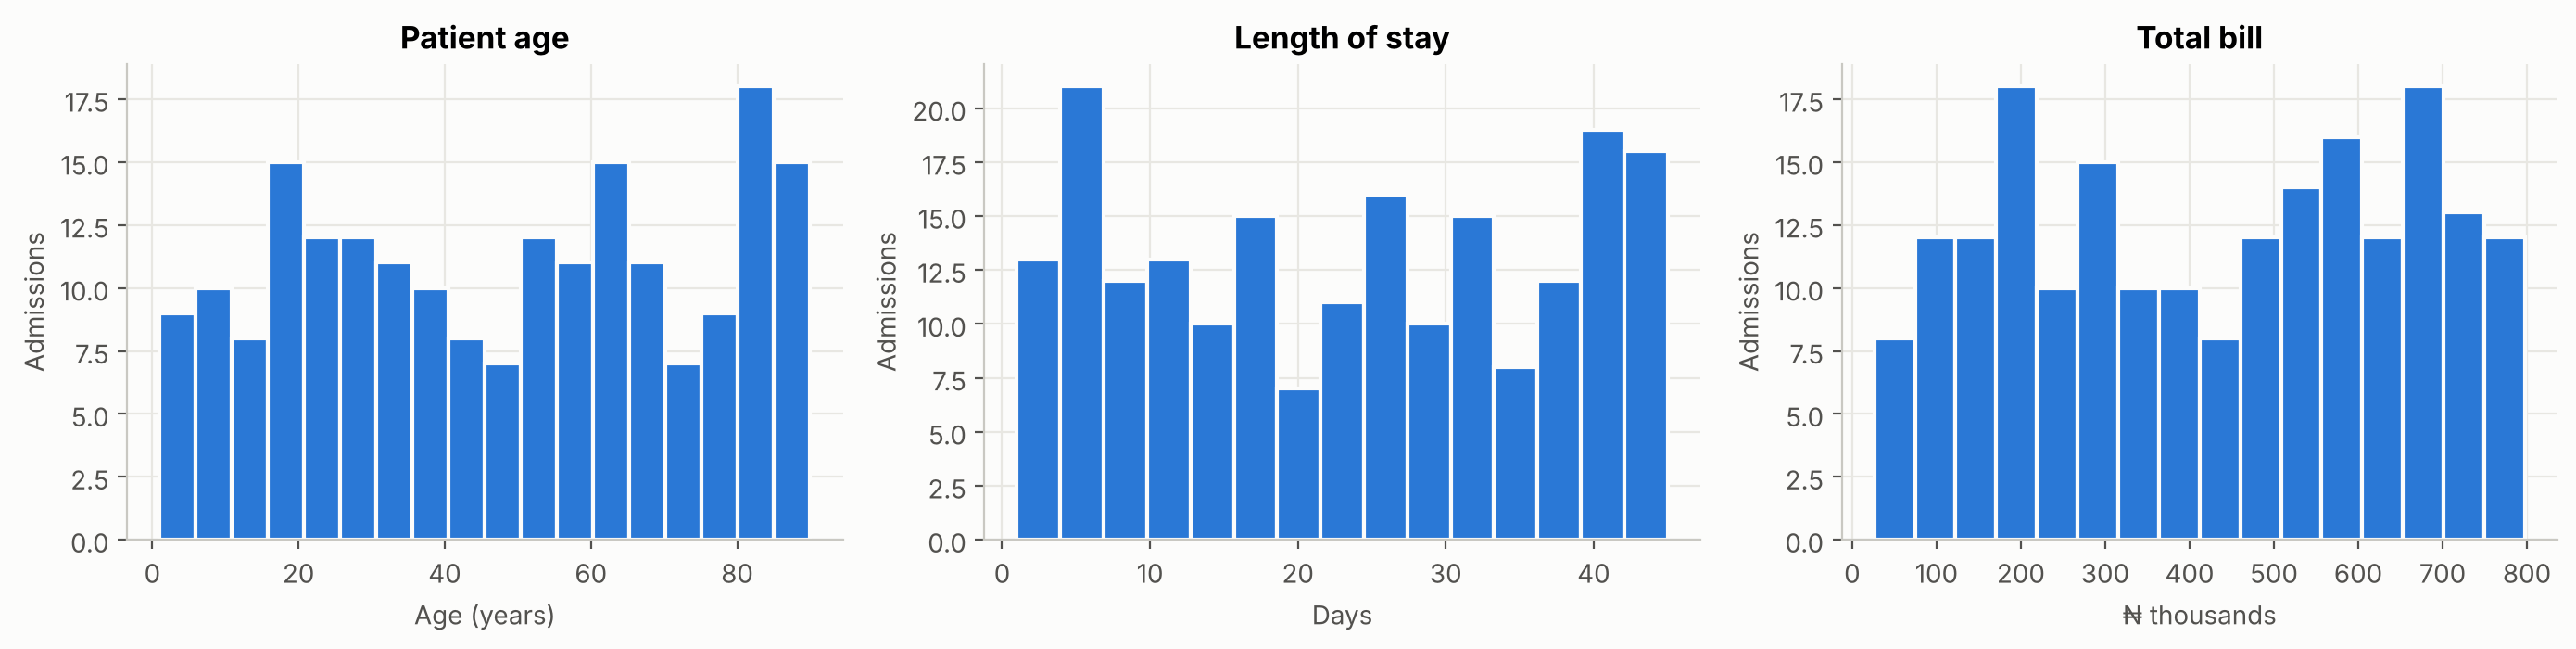

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].hist(df.age, bins=18, color=BLUE, edgecolor='#fcfcfb', linewidth=1.5); axes[0].set_title('Patient age'); axes[0].set_xlabel('Age (years)')
axes[1].hist(df.length_of_stay_days, bins=15, color=BLUE, edgecolor='#fcfcfb', linewidth=1.5); axes[1].set_title('Length of stay'); axes[1].set_xlabel('Days')
axes[2].hist(df.total_cost_ngn / 1000, bins=16, color=BLUE, edgecolor='#fcfcfb', linewidth=1.5); axes[2].set_title('Total bill'); axes[2].set_xlabel('₦ thousands')
for a in axes: a.set_ylabel('Admissions')
plt.tight_layout(); plt.savefig(IMG + 'distributions.png'); plt.show()

All three are close to **uniform** (flat) rather than bell-shaped, which is typical of synthetic training data. Real hospital LOS and cost are usually right-skewed.

### 6b. Correlation between length of stay and total cost

Pearson r = -0.059 (p = 0.408) | Spearman rho = -0.056 (p = 0.432)


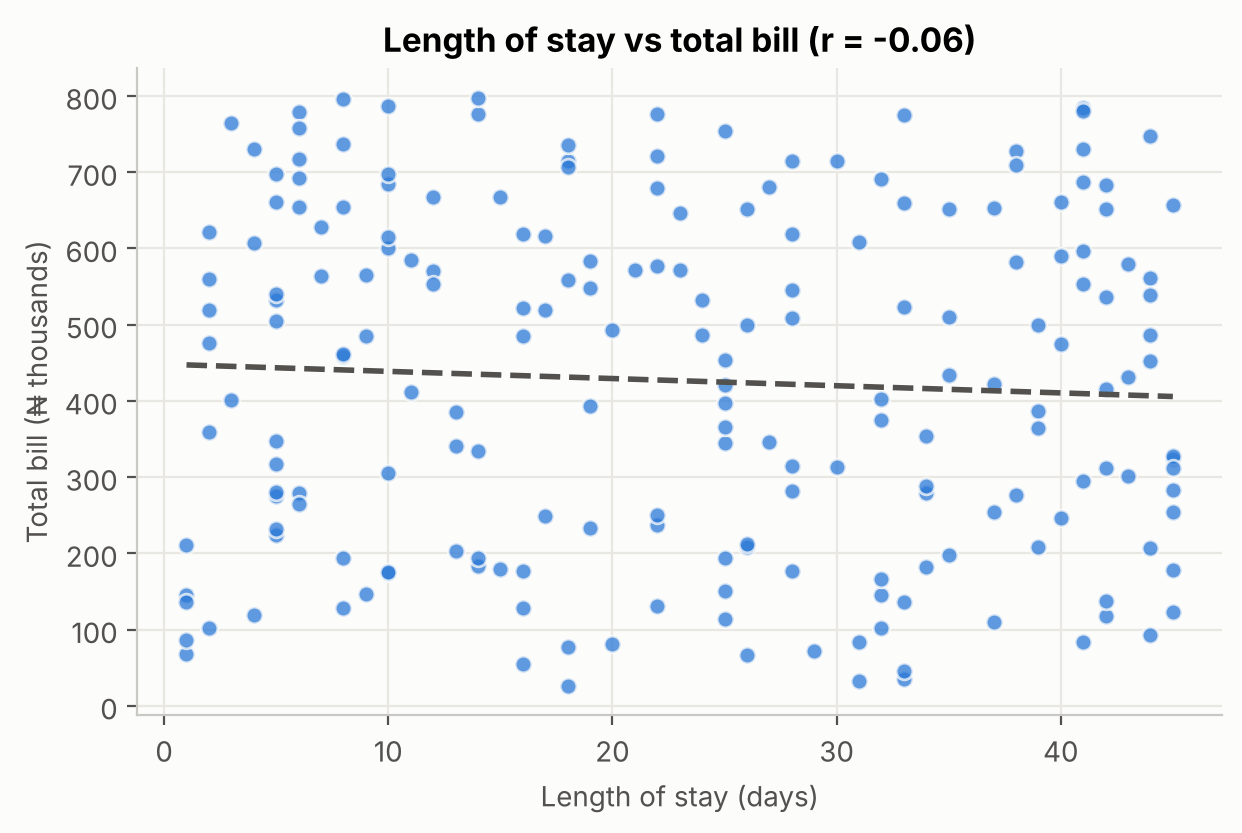

In [14]:
r, p = stats.pearsonr(df.length_of_stay_days, df.total_cost_ngn)
rho, p_s = stats.spearmanr(df.length_of_stay_days, df.total_cost_ngn)
print(f'Pearson r = {r:.3f} (p = {p:.3f}) | Spearman rho = {rho:.3f} (p = {p_s:.3f})')

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.scatter(df.length_of_stay_days, df.total_cost_ngn / 1000, s=36, color=BLUE, alpha=0.75, edgecolor='#fcfcfb', linewidth=1)
m, b = np.polyfit(df.length_of_stay_days, df.total_cost_ngn / 1000, 1)
xs = np.array([df.length_of_stay_days.min(), df.length_of_stay_days.max()])
ax.plot(xs, m * xs + b, color='#52514e', linewidth=2, linestyle='--')
ax.set_title(f'Length of stay vs total bill (r = {r:.2f})'); ax.set_xlabel('Length of stay (days)'); ax.set_ylabel('Total bill (₦ thousands)')
plt.savefig(IMG + 'los_vs_cost.png'); plt.show()

**Finding:** there is essentially **no relationship** between length of stay and total bill in this data (r close to 0, not significant). In a real hospital you would expect a strong positive link, because longer stays accumulate bed-day charges. This suggests billing here is driven by something other than days in bed (or that the data is randomly generated), and it is worth raising with the data owner.

A useful extra check: does cost track **procedures** instead?

In [15]:
print(df[['total_cost_ngn', 'length_of_stay_days', 'num_procedures', 'num_medications', 'nurse_ratio', 'age']].corr().round(2)['total_cost_ngn'])

total_cost_ngn         1.00
length_of_stay_days   -0.06
num_procedures         0.03
num_medications        0.05
nurse_ratio           -0.03
age                   -0.01
Name: total_cost_ngn, dtype: float64


### 6c. Readmission rate by age group

             admissions  readmissions  readmission_rate_%
age_group                                                
Child                35            12                34.3
Young Adult          42            30                71.4
Adult                48            28                58.3
Senior               75            39                52.0

Overall 30-day readmission rate: 54.5%


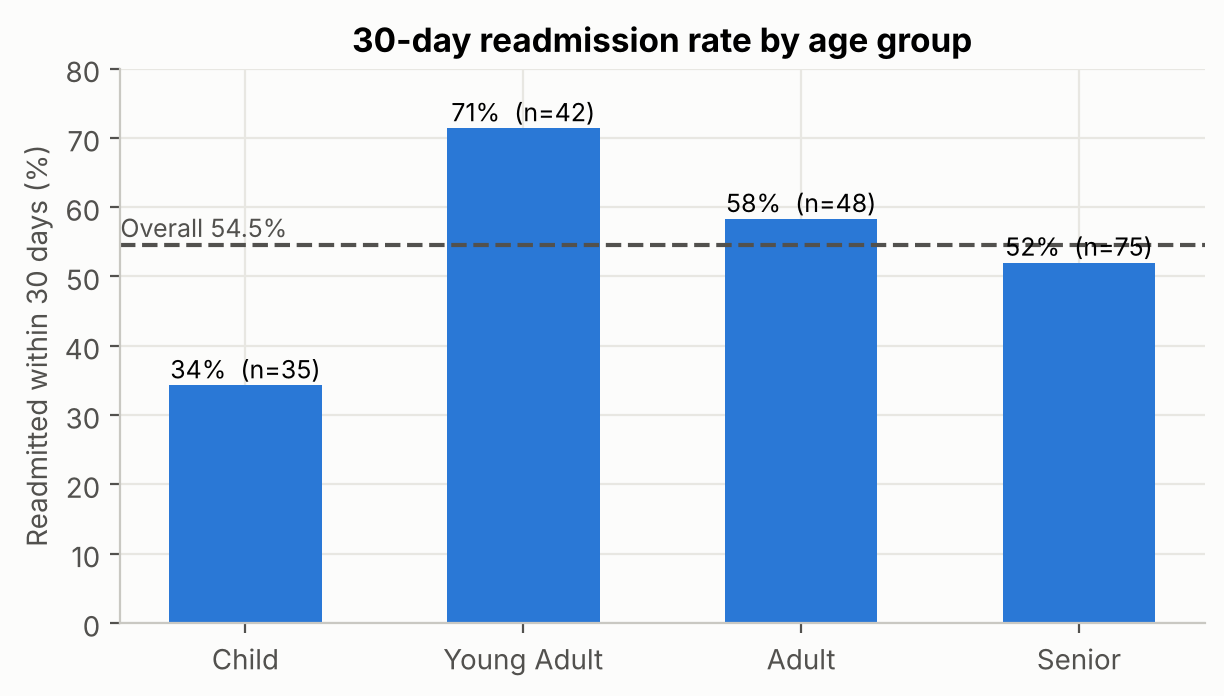

In [16]:
ra = df.groupby('age_group', observed=True).agg(admissions=('admission_id', 'count'),
                                                readmissions=('readmitted_within_30_days', 'sum'))
ra['readmission_rate_%'] = (ra.readmissions / ra.admissions * 100).round(1)
print(ra)
print(f"\nOverall 30-day readmission rate: {df.readmitted_within_30_days.mean()*100:.1f}%")

fig, ax = plt.subplots(figsize=(7, 3.6))
bars = ax.bar(ra.index.astype(str), ra['readmission_rate_%'], color=BLUE, width=0.55)
ax.axhline(df.readmitted_within_30_days.mean() * 100, color='#52514e', linestyle='--', linewidth=1.5)
ax.text(-0.45, df.readmitted_within_30_days.mean() * 100 + 1.2, f'Overall {df.readmitted_within_30_days.mean()*100:.1f}%', ha='left', color='#52514e', fontsize=9)
for bar, n, v in zip(bars, ra.admissions, ra['readmission_rate_%']):
    ax.text(bar.get_x() + bar.get_width() / 2, v + 1, f'{v:.0f}%  (n={n})', ha='center', fontsize=9)
ax.set_ylim(0, 80); ax.set_ylabel('Readmitted within 30 days (%)'); ax.set_title('30-day readmission rate by age group')
plt.savefig(IMG + 'readmission_by_age.png'); plt.show()

### 6d. Mortality trend by month

About 6 admissions a month means a monthly rate jumps between 0% and 50% from just one or two deaths. So we plot the monthly rate faintly and add a **3-month rolling rate** (deaths ÷ admissions over the window) to show the trend.

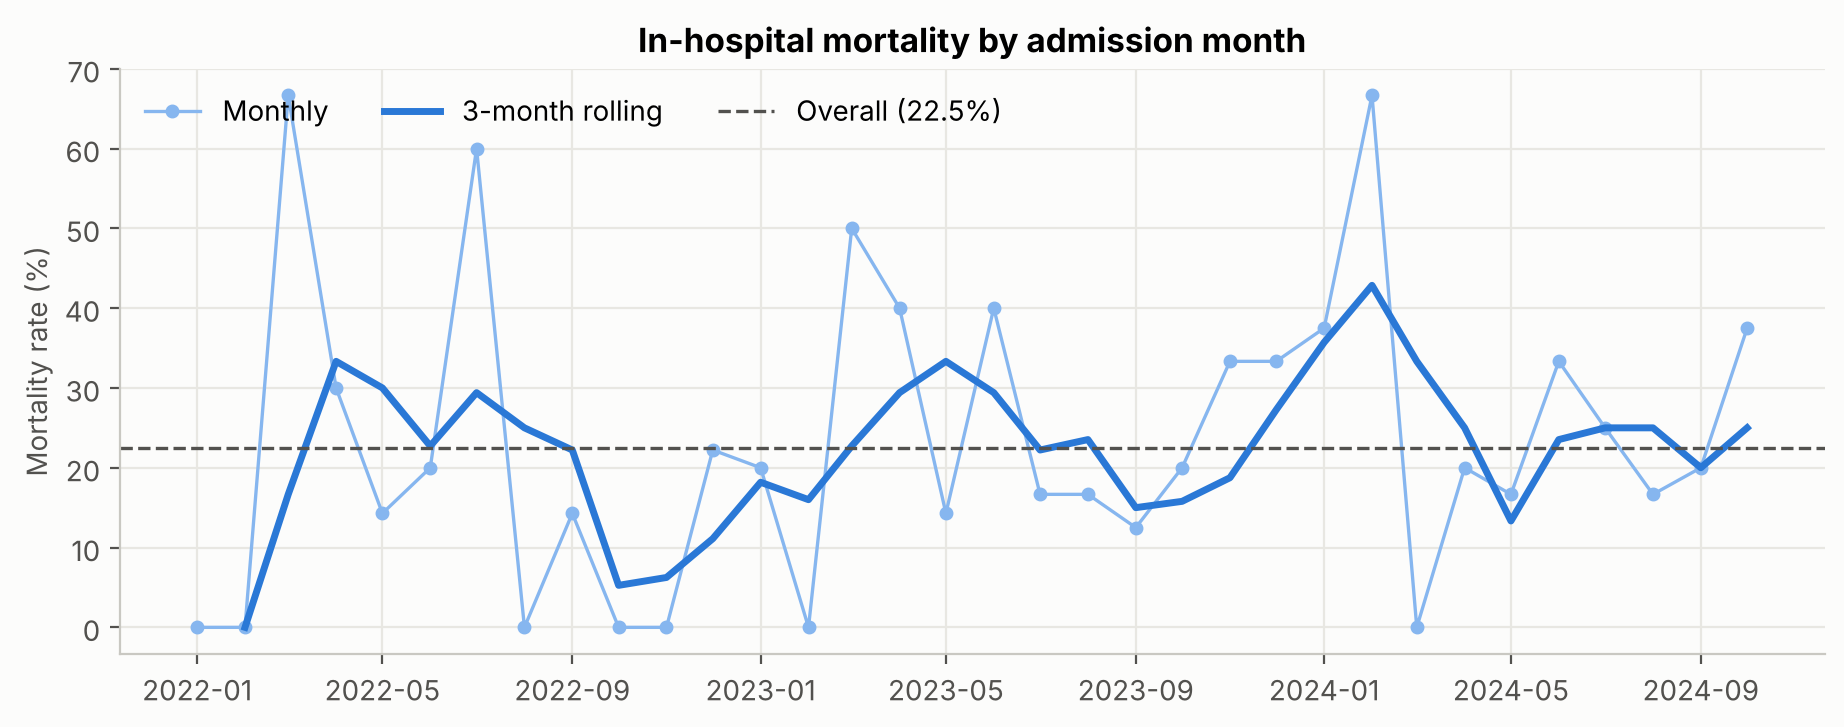

,admissions,deaths,mortality_%,rolling_3m_%
2024-06,6,2,33.333333,23.529412
2024-07,4,1,25.000000,25.000000
2024-08,6,1,16.666667,25.000000
2024-09,10,2,20.000000,20.000000
2024-10,8,3,37.500000,25.000000


In [17]:
mon = df.groupby('admission_month').agg(admissions=('admission_id', 'count'), deaths=('died', 'sum'))
idx = pd.period_range(df.admission_date.min(), df.admission_date.max(), freq='M').astype(str)
mon = mon.reindex(idx, fill_value=0)
mon['mortality_%'] = np.where(mon.admissions > 0, mon.deaths / mon.admissions * 100, np.nan)
roll = mon[['deaths', 'admissions']].rolling(3, min_periods=2).sum()
mon['rolling_3m_%'] = roll.deaths / roll.admissions * 100

fig, ax = plt.subplots(figsize=(11, 3.8))
x = pd.to_datetime(mon.index)
ax.plot(x, mon['mortality_%'], color='#86b6ef', linewidth=1.2, marker='o', markersize=4, label='Monthly')
ax.plot(x, mon['rolling_3m_%'], color=BLUE, linewidth=2.5, label='3-month rolling')
ax.axhline(df.died.mean() * 100, color='#52514e', linestyle='--', linewidth=1.2, label=f'Overall ({df.died.mean()*100:.1f}%)')
ax.set_ylabel('Mortality rate (%)'); ax.set_title('In-hospital mortality by admission month'); ax.legend(frameon=False, ncol=3, loc='upper left')
plt.savefig(IMG + 'mortality_trend.png'); plt.show()
mon.tail()

### 6e. Heatmap — admissions by department and month

With 34 months and 200 rows, a department × year-month grid is mostly 0s and 1s. Grouping by **calendar month** (all years combined) shows seasonality more clearly.

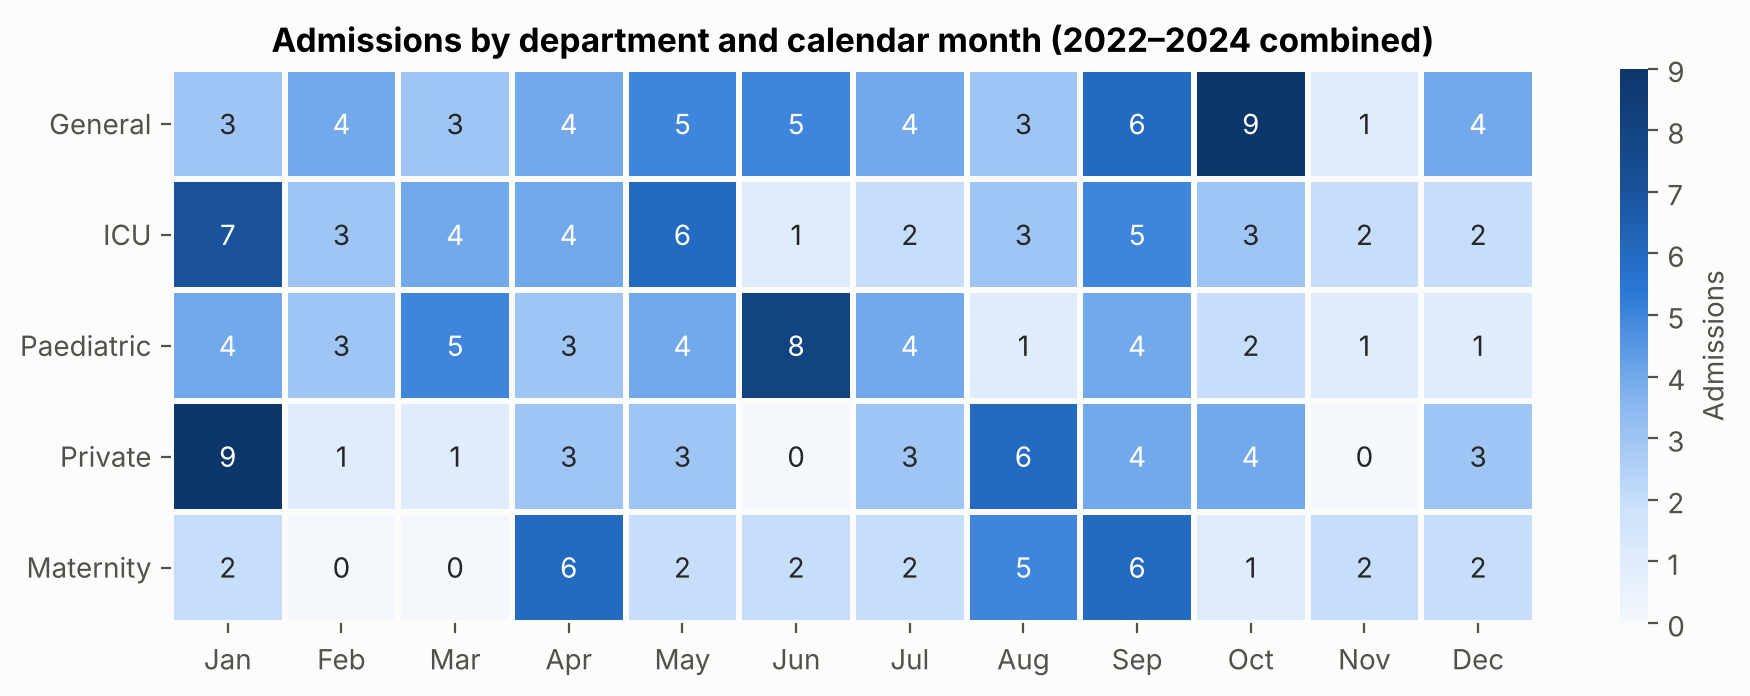

In [18]:
months = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']
heat = df.pivot_table(index='department', columns='admission_month_name', values='admission_id',
                      aggfunc='count', fill_value=0).reindex(columns=months, fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11, 3.6))
sns.heatmap(heat, annot=True, fmt='d', cmap=SEQ, linewidths=2, linecolor='#fcfcfb',
            cbar_kws={'label': 'Admissions'}, ax=ax)
ax.set_title('Admissions by department and calendar month (2022–2024 combined)'); ax.set_xlabel(''); ax.set_ylabel('')
plt.savefig(IMG + 'heatmap_dept_month.png'); plt.show()

### 6f. Box plot — cost by bed type

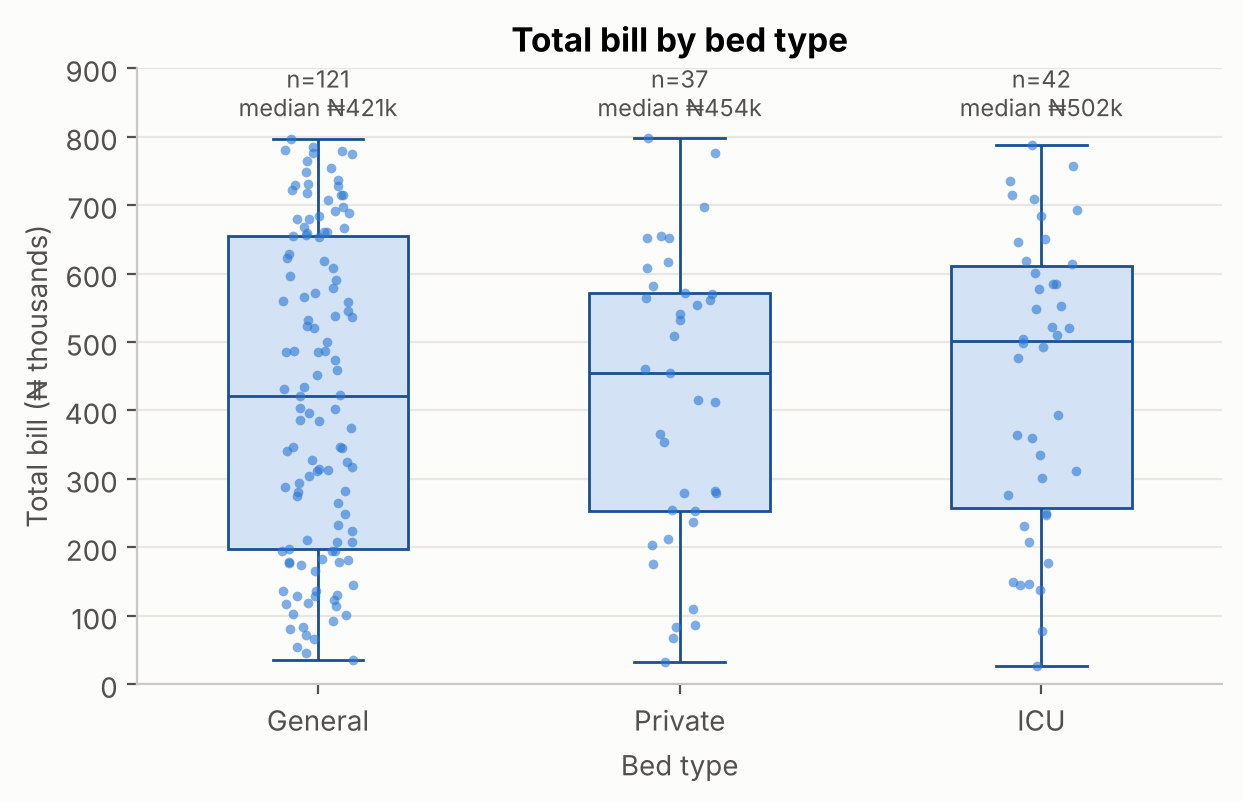

Kruskal-Wallis test across bed types: H = 0.37, p = 0.833


In [19]:
order = ['General', 'Private', 'ICU']
fig, ax = plt.subplots(figsize=(7, 4))
sns.boxplot(data=df, x='bed_type', y=df.total_cost_ngn / 1000, order=order, color='#cde2fb',
            linecolor='#184f95', width=0.5, ax=ax, fliersize=4)
sns.stripplot(data=df, x='bed_type', y=df.total_cost_ngn / 1000, order=order, color=BLUE, size=3.5, alpha=0.6, ax=ax)
for i, bt in enumerate(order):
    s = df.loc[df.bed_type == bt, 'total_cost_ngn']
    ax.text(i, 830, f'n={len(s)}\nmedian ₦{s.median()/1000:,.0f}k', ha='center', fontsize=8.5, color='#52514e')
ax.set_ylim(0, 900); ax.set_xlabel('Bed type'); ax.set_ylabel('Total bill (₦ thousands)'); ax.set_title('Total bill by bed type')
plt.savefig(IMG + 'cost_by_bed_type.png'); plt.show()

kw = stats.kruskal(*[df.loc[df.bed_type == b, 'total_cost_ngn'] for b in order])
print(f'Kruskal-Wallis test across bed types: H = {kw.statistic:.2f}, p = {kw.pvalue:.3f}')

## 7. Save the cleaned dataset

In [20]:
cols = ['admission_id', 'patient_id', 'hospital_id', 'state', 'admission_date', 'discharge_date',
        'admission_month', 'admission_quarter', 'admission_weekday', 'weekend_admission',
        'age', 'age_group', 'gender', 'insurance_type', 'department', 'bed_type', 'is_icu_admission',
        'treatment_type', 'primary_diagnosis', 'secondary_diagnosis', 'num_procedures', 'num_medications',
        'length_of_stay_days', 'total_cost_ngn', 'amount_paid_ngn', 'outstanding_ngn', 'collection_rate',
        'cost_per_day', 'discharge_outcome', 'died', 'readmitted_within_30_days', 'attending_doctor_id', 'nurse_ratio']
clean = df[cols].copy()
clean['admission_date'] = clean.admission_date.dt.date
clean['discharge_date'] = clean.discharge_date.dt.date
clean.to_csv('../data/cleaned_admissions.csv', index=False)
print(clean.shape, '-> data/cleaned_admissions.csv')

(200, 33) -> data/cleaned_admissions.csv


## Cleaning log (summary)
| Step | Result |
|---|---|
| Rows in / out | 200 / 200 (no rows dropped — `Died` rows kept) |
| Duplicates | 0 |
| Date parsing | 0 failures; 0 discharges before admission |
| LOS recalculated | matches supplied column on every row; min 1 day, so `cost_per_day` is safe |
| Nulls | `secondary_diagnosis` 22 → `'No secondary'`; 21 rows where secondary = primary → `'No secondary'` |
| Relabelled | discharge outcome to brief's labels |
| Plausibility | adults in Paediatrics and males in Maternity flagged (kept, caveated) |
| Columns added | 13 engineered features |